# Scouting geométrico

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

df_raw = pd.read_csv("../datasets/players_data-2025_2026.csv")

---
### Fase 1: Construyendo el Multiverso del Jugador

Jugador estrella: el máximo goleador del dataset.

In [2]:
features = ["Gls", "Ast", "Min", "Sh", "SoT"]

df = df_raw[["Player", "Squad", "Pos"] + features].copy()
df[features] = df[features].astype(float)
df = df.sort_values("Min", ascending=False).drop_duplicates("Player").reset_index(drop=True)

estrella = df.loc[df["Gls"].idxmax(), "Player"]
print("Jugador estrella:", estrella)
df[df["Player"] == estrella]

Jugador estrella: Harry Kane


,Player,Squad,Pos,Gls,Ast,Min,Sh,SoT
446,Harry Kane,Bayern Munich,"FW,MF",36.0,5.0,2377.0,119.0,67.0


**Pregunta de control:** hay que **escalar / normalizar** las columnas. Sin esto, `Min` (miles) domina la distancia y `Gls` (decenas) casi no aporta.
Usamos estandarización (Z-score): $z = \frac{x - \mu}{\sigma}$, así cada columna queda con media 0 y desviación 1.

In [3]:
X = StandardScaler().fit_transform(df[features])

idx_estrella = df.index[df["Player"] == estrella][0]
v_estrella = X[idx_estrella]
X_candidatos = np.delete(X, idx_estrella, axis=0)
candidatos = df.drop(idx_estrella).reset_index(drop=True)

print("Vector estrella:", v_estrella.round(3))
print("Matriz candidatos:", X_candidatos.shape)

Vector estrella: [11.465  2.035  1.151  5.379  8.   ]
Matriz candidatos: (2686, 5)


---
### Fase 2: El Duelo de Distancias

**Distancia Euclidiana (L2):**
$$d(p, q) = \sqrt{\sum_{i=1}^{n} (p_i - q_i)^2}$$

**Distancia Manhattan (L1):**
$$d(p, q) = \sum_{i=1}^{n} |p_i - q_i|$$

In [4]:
dist_euc = np.sqrt(((X_candidatos - v_estrella) ** 2).sum(axis=1))
reemplazo_euc = candidatos.loc[dist_euc.argmin(), "Player"]

print("Reemplazo (Euclidiana):", reemplazo_euc, "| distancia:", round(dist_euc.min(), 3))

Reemplazo (Euclidiana): Erling Haaland | distancia: 3.638


In [5]:
def manhattan(p, q):
    return np.abs(q - p).sum(axis=1)

dist_man = manhattan(v_estrella, X_candidatos)
reemplazo_man = candidatos.loc[dist_man.argmin(), "Player"]

print("Reemplazo (Manhattan):", reemplazo_man, "| distancia:", round(dist_man.min(), 3))

Reemplazo (Manhattan): Kylian Mbappé | distancia: 5.844


In [6]:
ranking = candidatos[["Player", "Squad"]].copy()
ranking["Euclidiana"] = dist_euc
ranking["Manhattan"] = dist_man
ranking.sort_values("Euclidiana").head(5)

,Player,Squad,Euclidiana,Manhattan
134,Erling Haaland,Manchester City,3.638492,6.628679
311,Kylian Mbappé,Real Madrid,3.982681,5.843649
62,Vedat Muriqi,Mallorca,5.394882,9.752939
32,Igor Thiago,Brentford,6.367518,12.727270
531,Deniz Undav,Stuttgart,6.408105,9.897785


**Análisis crítico:** ANALISIS_PLACEHOLDER

---
### Fase 3: Visualización en 4D+ (Gráfico de Radar)

Un gráfico de radar pone cada característica en un eje radial, así podemos comparar los 5 valores (escalados) de cada jugador en una sola figura 2D.

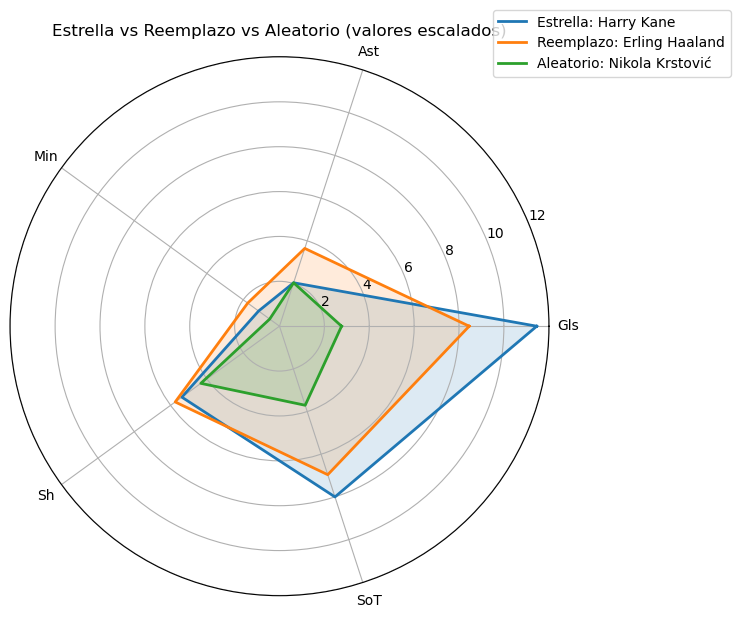

In [7]:
np.random.seed(42)
aleatorio = candidatos.loc[np.random.randint(len(candidatos)), "Player"]

jugadores = {
    f"Estrella: {estrella}": v_estrella,
    f"Reemplazo: {reemplazo_euc}": X_candidatos[dist_euc.argmin()],
    f"Aleatorio: {aleatorio}": X_candidatos[candidatos.index[candidatos["Player"] == aleatorio][0]],
}

angulos = np.linspace(0, 2 * np.pi, len(features), endpoint=False).tolist()
angulos += angulos[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"polar": True})
for nombre, v in jugadores.items():
    valores = v.tolist() + v[:1].tolist()
    ax.plot(angulos, valores, linewidth=2, label=nombre)
    ax.fill(angulos, valores, alpha=0.15)

ax.set_xticks(angulos[:-1])
ax.set_xticklabels(features)
ax.set_title("Estrella vs Reemplazo vs Aleatorio (valores escalados)")
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1))
plt.show()

In [8]:
df[df["Player"].isin([estrella, reemplazo_euc, aleatorio])]

,Player,Squad,Pos,Gls,Ast,Min,Sh,SoT
134,Erling Haaland,Manchester City,FW,27.0,8.0,2953.0,126.0,59.0
446,Harry Kane,Bayern Munich,"FW,MF",36.0,5.0,2377.0,119.0,67.0
861,Nikola Krstović,Atalanta,FW,10.0,5.0,1791.0,99.0,34.0


La forma del reemplazo casi se superpone con la de la estrella, mientras que el jugador aleatorio queda lejos, los vectores de la estrella y su clon están cerca en el hiperespacio.